# What Is an LLM? A Mental Model for Software Engineers

An original Beyond the Stack article companion. The numbered sections match the article.
Follow a synthetic delivery update from text to tokens, numerical representations, and generated text.
Read the accompanying article: [What Is an LLM? A Mental Model for Software Engineers](https://blog.beyondthestack.dev/what-is-an-llm/).

**Run:** select the environment described in the README, restart the kernel, and run all cells in order.
The first run downloads approximately 1 GB of Qwen weights plus tokenizer files. CPU inference uses
additional memory (float32 weights alone are about 2 GB). There are no paid API calls or training steps.
W&B logging is optional and offline; uploading would require a separate deliberate action.
Saved outputs are evidence of a particular run, not a promise of identical wording or speed elsewhere.

## High-level overview of LLM

### Prefill

1. The application formats the system and user messages using Qwen’s chat template. In our example, the result contains **68 token IDs**: the system message, delivery prompt, role markers, and opening assistant marker. The delivery prompt alone contains 49 tokens.

2. Each ID selects a **896-value initial embedding** from the model’s learned input embedding table. We now have one vector for each input position. The same token ID can appear at several positions.

3. The 68 representations pass through **24 transformer blocks in sequence**. Each block creates its own queries, keys, and values (**Q/K/V**) from the representations it receives. It uses them in attention, applies its other operations, and sends updated representations to the next block. Block 1 works from the initial embeddings; later blocks work from representations updated by earlier blocks.

4. This model uses **causal attention**: each position can use itself and earlier positions, but cannot use later positions. The first position is still updated because it can attend to itself and undergo the block’s other operations. The final input position can use the entire supplied prefix. This restriction supports **causal language modeling**, in which the model predicts the next token from the prefix available so far. Other model setups include **masked language modeling**, which predicts hidden tokens using surrounding text, and **encoder–decoder models**, which generate an output using a separately processed input.

5. After block 24, there is one final 896-value representation for each of the 68 input positions. This **first forward pass** through the complete supplied input is called **prefill**. During it, each block also produces keys and values for its positions that can be cached for later generation steps.

### Overall flow: choosing the first answer token

1. **Format and tokenize:** Convert the system and user messages into the 68 token IDs the model expects.

2. **Look up embeddings:** Obtain 68 initial vectors, each with 896 values, from the trained embedding table.

3. **Process the input:** Pass those representations through all 24 transformer blocks. Each block creates and uses Q/K/V and updates the representations. This is the prefill pass.

4. **Take the last position’s final vector:** Select its 896-value representation. Because of causal attention, that position has access to the whole supplied prefix.

5. **Score possible next tokens:** The model’s final output layer, **`lm_head`**, transforms that vector into **151,936 logits**. It is a linear layer shown in the notebook as `Linear(in_features=896, out_features=151936, bias=False)`. In simplified notation:

   ```text
   logits = W × final_vector
   ```

   Here, `W` is the output layer’s learned matrix. The result contains one logit for each numbered output position associated with a possible token ID. These positions are sometimes informally called *output slots*; **vocabulary size** is the count of them, not a synonym for one slot. The model’s configured output size is 151,936, which can be larger than the tokenizer’s count of assigned tokens. The layer scores the full output before the notebook displays only the leading candidates.

6. **Choose one token ID:** Apply a **decoding strategy** to the logits. Greedy decoding chooses the highest-scoring ID. Sampling uses softmax to make a probability distribution and draws an ID; **temperature** changes how concentrated that distribution is. Other widely used selection methods include *top-k* and *top-p* sampling, which restrict the candidates considered for a draw, and *beam search*, which tracks several possible continuations. The notebook focuses on greedy decoding and sampling.

   **Scoring** is the model’s calculation of logits; **choosing** is the decoding strategy applied afterward. The notebook also calculates softmax probabilities for inspection, although greedy selection can use the logits directly. A next-token probability does not establish that the answer is factually correct.

7. **Append the selected ID:** This is answer token 1. The logits that led to it came from prefill. The token itself has **not yet passed through the transformer blocks**; that happens in the next pass, when the model predicts answer token 2.

### The generation loop (prefill-decoding-decoding-...-end of response token)

```text
Prefill: process all 68 input positions through blocks 1–24
  → score possible next tokens using the last input position
  → choose and append answer token 1

Decode step: look up answer token 1’s initial embedding
  → pass its position through blocks 1–24
  → in each block, create Q/K/V for this new position
     and use that block’s cached keys and values from earlier positions
  → score possible next tokens using its final representation
  → choose and append answer token 2

Decode step: process answer token 2 in the same way
  → score, choose, and append answer token 3

Repeat decode steps until an end-of-response token is selected
or a configured generation limit is reached.
```

Both **prefill** and a **decode step** use the embedding lookup and transformer blocks. Prefill processes the supplied input positions. With the cache enabled, each subsequent decode step processes the newly appended position and reuses keys and values saved for earlier positions.

The new token starts at block 1 with its **own initial embedding**. It does not start with the earlier input’s final block-24 representations. Each block uses **its own cached keys and values** from prefill and preceding decode steps.

### Ending the response

The model can select a special **end-of-response token** when it predicts the next token. The generation code recognizes that token ID and stops. The model learned when such a token tends to occur, but it may stop too early or continue longer than intended.

A configured generation limit provides another stopping condition. In this notebook, `MAX_NEW_TOKENS = 64`, so generation stops after at most 64 new tokens even if the model has not selected an end-of-response token. Reaching that limit does not mean the answer is complete.

## 1. You send a prompt. What actually happens?

We want a customer-facing sentence based only on the supplied update. How does text become
model input? Where did the model's ability to write come from? How is the answer produced?
We will return to an actual generated response in Section 5, after inspecting the input.
This is synthetic data; no customer records or notification service are involved.

In [1]:
PROMPT = (
    'Summarize this delivery update in one sentence to notify the customer:\n'
    '“Order 482 was scheduled for 18:00. The driver reports a van breakdown. '
    'The revised arrival time is 18:25.”'
)
print(PROMPT)

Summarize this delivery update in one sentence to notify the customer:
“Order 482 was scheduled for 18:00. The driver reports a van breakdown. The revised arrival time is 18:25.”


## 2. What is an LLM, and where do its abilities come from?

A model is a neural network that performs numerical operations using learned **parameters**.
During pretraining, a causal language model is trained to predict subsequent tokens: an optimisation
procedure adjusts parameters to reduce prediction error across training examples.
Instruction tuning uses examples of instructions and desired responses to improve instruction following;
other post-training methods may follow. These stages differ from **inference**: using the trained model.

We load an instruction-tuned model, turn off training behaviour with `eval()`, and disable gradient
tracking. We do not train, update weights, or call an external generation API in this notebook.
`eval()` alone does not disable gradients; `inference_mode()` below does that for the forward passes.

- [Causal language modeling — Hugging Face](https://huggingface.co/docs/transformers/v4.57.1/en/tasks/language_modeling)
- [Instruction following with human feedback — Ouyang et al., 2022](https://arxiv.org/abs/2203.02155)
- [Selected model card — Qwen team](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct)

In [2]:
import importlib.metadata as metadata
import json
import os
import platform
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

# Suppress two known environment notices; no package changes are needed for this demo.
warnings.filterwarnings('ignore', message='urllib3 v2 only supports OpenSSL.*')
warnings.filterwarnings('ignore', message='IProgress not found.*')
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig

MODEL_ID = 'Qwen/Qwen2.5-0.5B-Instruct'
MODEL_REVISION = '7ae557604adf67be50417f59c2c2f167def9a775'
DEVICE = 'cpu'  # Portable teaching baseline; timings are not production benchmarks.
DTYPE = torch.float32  # Store floating-point model weights as 32-bit numbers.
torch.set_num_threads(2)
MAX_NEW_TOKENS = 64
TRACE_STEPS = 8
SEEDS = [7, 19]
LOG_WANDB = False  # Optional: change to True to record tables offline in Section 7.

versions = {name: metadata.version(name) for name in (
    'torch', 'transformers', 'tokenizers', 'huggingface-hub',
    'safetensors', 'pandas', 'matplotlib', 'nbformat', 'ipykernel'
)}
manifest = {
    'model_id': MODEL_ID, 'revision': MODEL_REVISION,
    'python': platform.python_version(), 'platform': platform.platform(),
    'device': DEVICE, 'dtype': str(DTYPE), 'torch_threads': torch.get_num_threads(),
    'versions': versions, 'started_at_utc': datetime.now(timezone.utc).isoformat(),
}
display(pd.DataFrame(versions.items(), columns=['package', 'version']))

# Default Hugging Face cache; HF_HUB_CACHE can override its location before launch.
# On a fresh machine this downloads weights. Later runs can reuse the cache.
# Select the causal language model architecture and load its pretrained configuration and weights.
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, dtype=DTYPE,
    attn_implementation='eager',  # Explicit, inspectable baseline.
).to(DEVICE)
model.eval()  # Use evaluation behavior, such as disabling dropout where present.
model.requires_grad_(False)  # Do not calculate gradients for model parameters.

,package,version
0,torch,2.8.0
1,transformers,4.57.6
2,tokenizers,0.22.2
3,huggingface-hub,0.36.2
4,safetensors,0.7.0
5,pandas,2.3.3
6,matplotlib,3.9.4
7,nbformat,5.10.4
8,ipykernel,6.31.0


Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (rotary_emb): Qwen2

In [3]:
config_summary = pd.DataFrame([
    ('architecture', model.config.model_type),
    ('parameters', sum(p.numel() for p in model.parameters())),
    ('transformer blocks', model.config.num_hidden_layers),
    ('representation width', model.config.hidden_size),
    ('input embedding shape / vocabulary size', tuple(model.get_input_embeddings().weight.shape)), # 
    ('training mode', model.training),
], columns=['property', 'value'])
display(config_summary)
assert not model.training
assert not any(p.requires_grad for p in model.parameters())

,property,value
0,architecture,qwen2
1,parameters,494032768
2,transformer blocks,24
3,representation width,896
4,input embedding shape / vocabulary size,"(151936, 896)"
5,training mode,False


These are real properties of the loaded model, not measurements of intelligence or reliability.
The parameters carry learned patterns; this prompt provides the specific delivery facts for this request.
The model has not looked up a live order or learned a new delivery policy from its identifier.
The model printout is a map of its components, not a generated answer. `Embedding(151936, 896)`
means the input embedding table has 151,936 rows, each containing 896 learned values. A token ID
selects a row. The tokenizer vocabulary is its set of distinct tokens, and its vocabulary size is the
number of those tokens. The model's configured vocabulary size (151,936) gives the embedding table
capacity; it can be larger than the tokenizer's actual vocabulary size. This count describes token
types, not the number of token positions that fit in the context window.
The model has 24 decoder blocks. Each block includes attention and an MLP (another transformation).
The final `lm_head` produces scores for possible next tokens.

Each block has 14 query heads and 2 key/value heads, each 64 values wide. Several query heads
share each key/value head; this is called grouped-query attention. `q_proj`, `k_proj`, and `v_proj`
are learned layers that create query, key, and value vectors from a position's current representation.
Attention uses queries and keys to weight information from the values at permitted positions.

`model.eval()` selects evaluation behavior; it does not disable gradient tracking by itself.
Gradients tell a training algorithm how changing each parameter would affect its objective.
`requires_grad_(False)` marks model parameters as not needing those calculations. The later
`torch.inference_mode()` blocks also disable gradient tracking during inference. None of these
settings trains the model or changes its learned weights.


## 3. How text becomes model input (prefill)

Use the tokenizer shipped with the model: its token IDs must match the model's embedding rows.
Its vocabulary size counts distinct tokens, including special tokens, not tokens in a particular prompt.
Qwen uses byte-level BPE; the tokenization algorithm itself is a follow-up topic.
Token IDs are lookup indices, not meanings, probabilities, or a ranking of words.

First inspect the prompt on its own. Then inspect the actual conversation format: the model's
**chat template** adds role boundaries and an assistant prefix. We explicitly include a generic
system instruction so the input is visible and controlled, rather than relying on a template default.

- [Qwen tokenization and chat templates](https://qwen.readthedocs.io/en/latest/getting_started/concepts.html)
- [Hugging Face chat templates](https://huggingface.co/docs/transformers/v4.57.1/en/chat_templating)

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)

def token_table(ids):
    return pd.DataFrame([
        {
            'position': position,
            'token_id': token_id,
            'vocabulary_piece': tokenizer.convert_ids_to_tokens(token_id),
            'decoded_piece': repr(tokenizer.decode([token_id])),
            'special_token': token_id in tokenizer.all_special_ids,
        }
        for position, token_id in enumerate(ids)
    ])

raw_ids = tokenizer.encode(PROMPT, add_special_tokens=False)
raw_tokens = token_table(raw_ids)
display(raw_tokens)
print('Prompt token count:', len(raw_ids))
assert tokenizer.decode(raw_ids) == PROMPT

,position,token_id,vocabulary_piece,decoded_piece,special_token
0,0,9190,Sum,'Sum',False
1,1,5612,mar,'mar',False
2,2,551,ize,'ize',False
3,3,419,Ġthis,' this',False
4,4,9691,Ġdelivery,' delivery',False
5,5,2647,Ġupdate,' update',False
6,6,304,Ġin,' in',False
7,7,825,Ġone,' one',False
8,8,11652,Ġsentence,' sentence',False
9,9,311,Ġto,' to',False


Prompt token count: 49


The vocabulary spelling can contain space or byte markers. Also, decoding one byte-level token
alone can show a replacement character when its bytes form only part of a Unicode character.
That is why the full-sequence round-trip check matters; isolated pieces need not look like words.

In [5]:
MESSAGES = [
    {'role': 'system', 'content': 'You are a helpful assistant.'},
    {'role': 'user', 'content': PROMPT},
]
# readable form
formatted_prompt = tokenizer.apply_chat_template(
    MESSAGES, tokenize=False, add_generation_prompt=True,
)

# not much readable - the actual tokens to go in a model's input
inputs = tokenizer.apply_chat_template(
    MESSAGES, tokenize=True, add_generation_prompt=True,
    return_dict=True, return_tensors='pt',
).to(DEVICE)

input_ids = inputs['input_ids']
input_length = input_ids.shape[1]
print('Actual formatted input:\n')
print(formatted_prompt)
print('Prompt alone:', len(raw_ids), 'tokens')
print('Complete model input:', input_length, 'tokens')
display(token_table(input_ids[0].tolist()).head(18))
assert tokenizer.encode(formatted_prompt, add_special_tokens=False) == input_ids[0].tolist()

Actual formatted input:

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Summarize this delivery update in one sentence to notify the customer:
“Order 482 was scheduled for 18:00. The driver reports a van breakdown. The revised arrival time is 18:25.”<|im_end|>
<|im_start|>assistant

Prompt alone: 49 tokens
Complete model input: 68 tokens


,position,token_id,vocabulary_piece,decoded_piece,special_token
0,0,151644,<|im_start|>,'<|im_start|>',True
1,1,8948,system,'system',False
2,2,198,Ċ,'\n',False
3,3,2610,You,'You',False
4,4,525,Ġare,' are',False
5,5,264,Ġa,' a',False
6,6,10950,Ġhelpful,' helpful',False
7,7,17847,Ġassistant,' assistant',False
8,8,13,.,'.',False
9,9,151645,<|im_end|>,'<|im_end|>',True


### Getting the initial **embeddings vector** for input tokens (prefill)

In [8]:
with torch.inference_mode():
    embedding_table = model.get_input_embeddings()  # Access the model's input embedding layer - from training
    input_embeddings = embedding_table(input_ids)  # Look up a vector for each input token ID.
    
print('Token IDs shape:', tuple(input_ids.shape), '(batch, positions)')
print('Embedding shape:', tuple(input_embeddings.shape), '(batch, positions, width)')
print('First token, first 8 embedding values:', input_embeddings[0, 0, :8].tolist())
assert input_embeddings.shape[:2] == input_ids.shape

Token IDs shape: (1, 68) (batch, positions)
Embedding shape: (1, 68, 896) (batch, positions, width)
First token, first 8 embedding values: [0.0013885498046875, -0.0084228515625, 0.00732421875, -0.0015869140625, -0.0079345703125, 0.00494384765625, -0.007659912109375, 0.01263427734375]


An embedding is a learned numerical representation, looked up here using the token ID.
The input embedding table has one row per model vocabulary slot; the tensor displayed above instead
has one representation per input position. Repeated token IDs can occupy multiple input positions.
The few displayed coordinates do not individually label concepts such as “delay” or “customer”.
Qwen also supplies position information through rotary position embeddings inside attention;
the lookup tensor above is not the complete position-aware processing of the prompt.

## 4. How the model uses the surrounding text (prefill - **attention calculation**)

A **position** is a token's place in the input sequence. The same token ID can occur at multiple
positions. Its initial embedding is the same lookup at each occurrence, but the representations can
change as the model processes their different contexts. (attention generation)

The model sends these representations through 24 repeated computational blocks. **Attention** is
an operation within each block that combines information from permitted positions; other operations
also transform the representations. A **transformer** is the architecture organising these blocks.
Qwen incorporates position information inside attention, so order matters too.

In this **causal** model, each position can use information from itself and earlier positions, not
later ones. For example, position 3 can use positions 1, 2 and 3. The final input position can draw
on the entire supplied prefix, including the instruction, order number, cause, and revised time.

After the blocks, we have one updated 896-value representation for each of the 68 input positions:
68 vectors, not 896 vectors. Each position's representation reflects only its permitted context.
The final position's representation is used to produce scores for the first answer token; once a
token is selected and appended, it becomes part of the context for generating the next token.

The returned **hidden states** are the numerical representations at the embedding stage and across
blocks. We inspect their shapes and a numerical summary, without claiming that a particular
coordinate, block, or attention head explains the answer. Attention equations and the details of
heads and Q/K/V are deferred to a separate article.

[Original Transformer paper — Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)


In [11]:
with torch.inference_mode():
    inspected = model(**inputs, output_hidden_states=True, use_cache=False)

# There is one initial embedding tensor plus one returned tensor per block.
# Qwen's final returned state includes its final normalisation.
state_rows = []
for index, state in enumerate(inspected.hidden_states):
    label = ("embedding lookup (initial model's emebeddings)" if index == 0 else
             'final normalised state' if index == model.config.num_hidden_layers else
             f'after block/layer {index}')
    state_rows.append({
        'stage': label, 'shape': str(tuple(state.shape)),
        'last_position_norm': state[0, -1].float().norm().item(),  # converting last token's 896 vector to single value - to show it is different from previous block
    })
display(pd.DataFrame(state_rows).iloc[[0, 1, -2, -1]])
print(inspected.logits.shape[:2])
print('Output scores shape:', tuple(inspected.logits.shape), '(batch, positions, vocabulary)')
assert len(inspected.hidden_states) == model.config.num_hidden_layers + 1

,stage,shape,last_position_norm
0,embedding lookup (initial model's emebeddings),"(1, 68, 896)",0.579821
1,after block/layer 1,"(1, 68, 896)",3.193251
23,after block/layer 23,"(1, 68, 896)",66.746880
24,final normalised state,"(1, 68, 896)",301.364136


torch.Size([1, 68])
Output scores shape: (1, 68, 151936) (batch, positions, vocabulary)


Each `state` is a tensor with shape `(1, 68, 896)`: one input sequence (could be more than 1 i.e. can process batch of messages/inputs), 68 token positions,
and 896 values per position. The one sequence is the complete formatted conversation, including
the system message, delivery prompt, role markers, and assistant prefix. The table shows three of
25 returned states: the initial embedding lookup, the state after block 1, and the final state after
block 24 and final normalization. State 0 is the lookup from the trained embedding table, before
attention. Inference does not update the table.

`state[0, -1]` selects the first (and only) sequence with `0`, then its last token position with
`-1`. It keeps all 896 values, so the result has shape `(896,)`. Python indices start at zero;
negative indices count from the end. At the final stage, that position's representation can draw
on the whole input prefix.

`last_position_norm` is the L2 norm of that 896-value vector: the square root of the sum of its
squared values. It is a single number describing the vector's magnitude. It is not a measure of
understanding or answer quality, and different vectors can have the same norm. The table shows
shapes and this limited numerical summary, not the full vectors or a complete comparison of them.

The model produces scores at every supplied position. For generation, we use the scores at the
**last position** to select the next token.


## 5. How an answer is generated (decoding step)

At each step the model returns **logits** (unnormalised scores) for vocabulary tokens.
**Softmax** turns these into a probability distribution. A decoder selects a token, appends it,
and repeats. Greedy decoding takes the highest score; sampling draws from a distribution.
Temperature rescales logits before sampling. None of these probabilities establishes factual truth.

We first expose eight real greedy steps. The full prompt is processed on the first pass
(prefill). Later passes process the newly selected token and reuse cached prior key/value states.
The cache is a computation optimisation, not conversation memory stored across independent requests.

[Transformers generation reference](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/text_generation)
and [caching explanation](https://huggingface.co/docs/transformers/v4.57.1/en/cache_explanation).

In [15]:
eos_config = model.generation_config.eos_token_id  # end-of-sequence token ID
print(eos_config)

[151645, 151643]


In [12]:
eos_config = model.generation_config.eos_token_id  # end-of-sequence token ID
EOS_IDS = set(eos_config if isinstance(eos_config, list) else [eos_config])
PAD_ID = tokenizer.pad_token_id  # Padding ID: Padding exists when you process several sequences together in a batch and they have different lengths
if PAD_ID is None:
    PAD_ID = next(iter(EOS_IDS))

selected_ids = []
candidate_token_rows = []
decoded_step_rows = []
probability_sums = []
past = None
step_input = input_ids
attention_mask = inputs['attention_mask'].clone()
first_logits = None

with torch.inference_mode():
    for step in range(TRACE_STEPS):
        output = model(
            input_ids=step_input, attention_mask=attention_mask,
            past_key_values=past, use_cache=True,
        )
        logits = output.logits[0, -1].float()
        if first_logits is None:
            first_logits = logits.clone()
        probabilities = torch.softmax(logits.double(), dim=-1)
        probability_sums.append(probabilities.sum().item())
        values, candidates = probabilities.topk(5)
        chosen = int(logits.argmax())
        
        # the candidate tokens with softmax (from logit) and ranking
        for rank, (candidate, probability) in enumerate(zip(candidates.tolist(), values.tolist()), 1):
            candidate_token_rows.append({
                'step': step + 1, 'rank': rank, 'token_id': candidate,
                'piece': repr(tokenizer.decode([candidate])),
                'probability': probability,
            })
        selected_ids.append(chosen)

        # result of each decoding step (8 here) 
        decoded_step_rows.append({
            'step': step + 1, 'selected_id': chosen,
            'selected_piece': repr(tokenizer.decode([chosen])),
            'generated_so_far': tokenizer.decode(selected_ids, skip_special_tokens=False),
        })
        past = output.past_key_values
        if chosen in EOS_IDS:
            break
        step_input = torch.tensor([[chosen]], device=DEVICE)
        attention_mask = torch.cat([
            attention_mask, attention_mask.new_ones((1, 1)),
        ], dim=1)

candidates_df = pd.DataFrame(candidate_token_rows)  # the candidate tokens with softmax (from logit) and ranking
steps_df = pd.DataFrame(decoded_step_rows)  # result of each decoding step (8 here) 
display(candidates_df[candidates_df['step'] <= 2])
display(steps_df)
assert all(abs(total - 1.0) < 1e-5 for total in probability_sums)
del past, output

,step,rank,token_id,piece,probability
0,1,1,785,'The',0.298447
1,1,2,4431,'Order',0.103310
2,1,3,32,'A',0.094836
3,1,4,5501,'Please',0.068357
4,1,5,38121,'Delivery',0.062146
5,2,1,9691,' delivery',0.243475
6,2,2,6002,' customer',0.202478
7,2,3,5579,' driver',0.181432
8,2,4,1973,' order',0.134751
9,2,5,220,' ',0.039878


,step,selected_id,selected_piece,generated_so_far
0,1,785,'The',The
1,2,9691,' delivery',The delivery
2,3,572,' was',The delivery was
3,4,13537,' scheduled',The delivery was scheduled
4,5,369,' for',The delivery was scheduled for
5,6,220,' ',The delivery was scheduled for
6,7,16,'1',The delivery was scheduled for 1
7,8,23,'8',The delivery was scheduled for 18


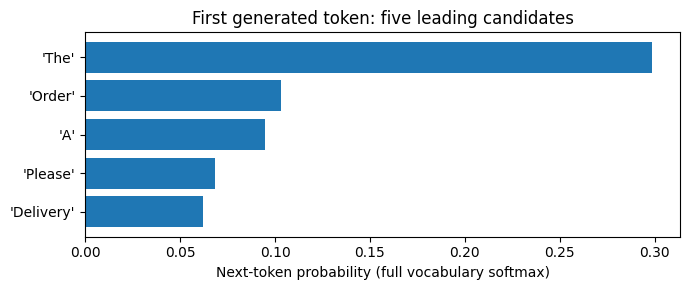

In [13]:
first_candidates = candidates_df[candidates_df['step'] == 1]
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(first_candidates['piece'][::-1], first_candidates['probability'][::-1])
ax.set(xlabel='Next-token probability (full vocabulary softmax)',
       title='First generated token: five leading candidates')
fig.tight_layout()
plt.show()
# Only the leading five are drawn; their probabilities need not sum to one.
# Inspection uses float64 softmax to reduce summation error over the large vocabulary.

Now generate a complete answer. We supply a fresh `GenerationConfig` so that sampling controls
in the model's default configuration cannot silently alter this comparison. The token limit
is a safety bound on output length, not a request to produce exactly that many tokens.
Timing below measures one local generation call, including prompt processing; it is not TTFT,
an isolated decode benchmark, or a comparison against a hosted production service.

In [16]:
def generate_answer(messages, do_sample=False, temperature=1.0, seed=7):
    encoded = tokenizer.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors='pt',
    ).to(DEVICE)
    sampling_options = {'temperature': temperature, 'top_k': 0, 'top_p': 1.0} if do_sample else {}
    settings = GenerationConfig(
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=do_sample, num_beams=1,
        repetition_penalty=1.0,
        eos_token_id=list(EOS_IDS), pad_token_id=PAD_ID,
        use_cache=True, **sampling_options,
    )
    torch.manual_seed(seed)
    started = time.perf_counter()
    with torch.inference_mode():
        result = model.generate(**encoded, generation_config=settings)  # runs all the steps till stop token
    elapsed = time.perf_counter() - started
    
    new_ids = result[0, encoded['input_ids'].shape[1]:].tolist()
    return {
        'method': 'sampling' if do_sample else 'greedy',
        'temperature': temperature if do_sample else None,
        'seed': seed if do_sample else None,
        'input_tokens': encoded['input_ids'].shape[1],
        'output_tokens': len(new_ids), 'elapsed_seconds': elapsed,
        'stop_reason': 'eos' if new_ids and new_ids[-1] in EOS_IDS else 'token_limit',
        'answer': tokenizer.decode(new_ids, skip_special_tokens=True),  # <---- generating text from sequence of token IDs
        'generated_ids': new_ids,
    }

greedy = generate_answer(MESSAGES)
print(greedy['answer'])
print('Stop:', greedy['stop_reason'])
assert greedy['generated_ids'][:len(selected_ids)] == selected_ids
print('Manual generation matches the built-in greedy prefix.')

The delivery was scheduled for 18:00, but the driver reports a van breakdown, so the revised arrival time is 18:25.
Stop: eos
Manual generation matches the built-in greedy prefix.


### 5.1 Change selection, keeping the model and prompt fixed

First compare the same first-token logits at two temperatures. This isolates the mathematical
effect without conflating it with different later contexts. Then generate two full sampled answers
at each temperature. Two seeds are illustrative, not an evaluation of quality or a statistical study.
Fixed seeds aid reproduction in a fixed environment; exact results can vary by hardware and software.

In [17]:
temperature_rows = []
for temperature in (0.4, 1.0):
    probabilities = torch.softmax(first_logits.double() / temperature, dim=-1)
    values, candidates = probabilities.topk(5)
    for rank, (candidate, probability) in enumerate(zip(candidates.tolist(), values.tolist()), 1):
        temperature_rows.append({
            'temperature': temperature, 'rank': rank,
            'piece': repr(tokenizer.decode([candidate])), 'probability': probability,
        })
display(pd.DataFrame(temperature_rows))

runs = [greedy]  # the previous greedy run
for temperature in (0.4, 1.0):
    for seed in SEEDS:
        runs.append(generate_answer(MESSAGES, do_sample=True, temperature=temperature, seed=seed))
run_table = pd.DataFrame([{k: v for k, v in row.items() if k != 'generated_ids'} for row in runs])
with pd.option_context('display.max_colwidth', 240):
    display(run_table)

,temperature,rank,piece,probability
0,0.4,1,'The',0.831754
1,0.4,2,'Order',0.058638
2,0.4,3,'A',0.047344
3,0.4,4,'Please',0.020882
4,0.4,5,'Delivery',0.016458
5,1.0,1,'The',0.298447
6,1.0,2,'Order',0.103310
7,1.0,3,'A',0.094836
8,1.0,4,'Please',0.068357
9,1.0,5,'Delivery',0.062146


,method,temperature,seed,input_tokens,output_tokens,elapsed_seconds,stop_reason,answer
0,greedy,NaN,NaN,68,34,1.851978,eos,"The delivery was scheduled for 18:00, but the driver reports a van breakdown, so the revised arrival time is 18:25."
1,sampling,0.4,7.0,68,25,1.422917,eos,The driver's van breakdown is causing an 18:00 to 18:25 delivery delay.
2,sampling,0.4,19.0,68,14,0.607951,eos,The delivery was delayed by one hour due to a van breakdown.
3,sampling,1.0,7.0,68,40,1.618705,eos,Delivery update: The original order for 482 has been updated to be at 18:25 when expected to be picked up. Tank damage is confirmed to be an issue.
4,sampling,1.0,19.0,68,40,1.589425,eos,"Order 482 is scheduled to arrive at 18:00, but the driver reports a van breakdown, so the pickup time will be 18:25 instead."


In [22]:
print(len(runs))
print(type(runs[0]))
print(runs[-1])

5
<class 'dict'>
{'method': 'sampling', 'temperature': 1.0, 'seed': 19, 'input_tokens': 68, 'output_tokens': 40, 'elapsed_seconds': 1.5894245409999712, 'stop_reason': 'eos', 'answer': 'Order 482 is scheduled to arrive at 18:00, but the driver reports a van breakdown, so the pickup time will be 18:25 instead.', 'generated_ids': [4431, 220, 19, 23, 17, 374, 13537, 311, 17331, 518, 220, 16, 23, 25, 15, 15, 11, 714, 279, 5579, 6682, 264, 5242, 29985, 11, 773, 279, 29586, 882, 686, 387, 220, 16, 23, 25, 17, 20, 4518, 13, 151645]}


## 6. Where the model ends and the system begins

The model generated text. An application must still decide whether to use it and send it.
Here the complete minimal path is:

**Synthetic delivery data → construct prompt → model → review → notification service.**

The final notification service is deliberately represented by a local preview. No message is sent.
An application could add retrieval (RAG), persistent memory, or tools; none is required for this
example. We do not implement them in this introductory notebook.

The checks below are deliberately limited: preserving two strings does not establish factual
accuracy, a correct cause, appropriate tone, exactly one sentence, or readiness for customers.
Do not treat these checks as a production guardrail or a general evaluation benchmark.

In [23]:
review_rows = []
for run in runs:
    answer = run['answer']
    review_rows.append({
        'method': run['method'], 'temperature': run['temperature'], 'seed': run['seed'],
        'contains_order_id': '482' in answer,
        'contains_revised_time': '18:25' in answer,
        'hit_token_limit': run['stop_reason'] == 'token_limit',
        'answer_for_human_review': answer,
    })
review_table = pd.DataFrame(review_rows)
with pd.option_context('display.max_colwidth', 240):
    display(review_table)

notification_preview = {
    'delivery_channel': 'preview_only',
    'sent': False,
    'human_review_required': True,
    'proposed_message': greedy['answer'],
}
display(notification_preview)
assert notification_preview['sent'] is False

,method,temperature,seed,contains_order_id,contains_revised_time,hit_token_limit,answer_for_human_review
0,greedy,NaN,NaN,False,True,False,"The delivery was scheduled for 18:00, but the driver reports a van breakdown, so the revised arrival time is 18:25."
1,sampling,0.4,7.0,False,True,False,The driver's van breakdown is causing an 18:00 to 18:25 delivery delay.
2,sampling,0.4,19.0,False,False,False,The delivery was delayed by one hour due to a van breakdown.
3,sampling,1.0,7.0,True,True,False,Delivery update: The original order for 482 has been updated to be at 18:25 when expected to be picked up. Tank damage is confirmed to be an issue.
4,sampling,1.0,19.0,True,True,False,"Order 482 is scheduled to arrive at 18:00, but the driver reports a van breakdown, so the pickup time will be 18:25 instead."


{'delivery_channel': 'preview_only',
 'sent': False,
 'human_review_required': True,
 'proposed_message': 'The delivery was scheduled for 18:00, but the driver reports a van breakdown, so the revised arrival time is 18:25.'}

Review the actual answers: do they preserve the revised time and van breakdown, make clear that
the delivery is delayed, address the customer, and avoid invented promises or compensation?
If a sample fails, keep it as evidence and discuss it. Do not quietly replace it with a written answer.

## 7. What this means when you build software

The prompt supplies the facts for this interaction. Training shaped the model before this request.
Tokenization and the chat template define its input. The model computes representations and scores;
the generation procedure selects a continuation. Your application owns what happens to that continuation.

The checks below establish mechanical properties of this walkthrough. They do not establish
general model reliability, verify all numerical weights, or benchmark production performance.

In [26]:
verification = {
    'prompt_round_trip': tokenizer.decode(raw_ids) == PROMPT, 
    'chat_template_ids_match': tokenizer.encode(formatted_prompt, add_special_tokens=False) == input_ids[0].tolist(),
    'probabilities_normalised': all(abs(total - 1.0) < 1e-5 for total in probability_sums),
    'manual_prefix_matches_generate': greedy['generated_ids'][:len(selected_ids)] == selected_ids,
    'all_runs_within_output_bound': all(0 < run['output_tokens'] <= MAX_NEW_TOKENS for run in runs),
    'no_notification_sent': notification_preview['sent'] is False,
}
assert all(verification.values()), verification
manifest.update({
    'max_new_tokens': MAX_NEW_TOKENS, 'trace_steps': TRACE_STEPS,
    'sampling_temperatures': [0.4, 1.0], 'seeds': SEEDS,
    'sampling_top_k': 0, 'sampling_top_p': 1.0,
    'attention_implementation': 'eager',
    'prompt': PROMPT, 'formatted_prompt': formatted_prompt,
    'verification': verification,
    'finished_at_utc': datetime.now(timezone.utc).isoformat(),
})
display(pd.DataFrame(verification.items(), columns=['check', 'passed']))
print(json.dumps({k: v for k, v in manifest.items() if k not in ('prompt', 'formatted_prompt')}, indent=2))

,check,passed
0,prompt_round_trip,True
1,chat_template_ids_match,True
2,probabilities_normalised,True
3,manual_prefix_matches_generate,True
4,all_runs_within_output_bound,True
5,no_notification_sent,True


{
  "model_id": "Qwen/Qwen2.5-0.5B-Instruct",
  "revision": "7ae557604adf67be50417f59c2c2f167def9a775",
  "python": "3.9.6",
  "platform": "macOS-26.6.2-arm64-arm-64bit",
  "device": "cpu",
  "dtype": "torch.float32",
  "torch_threads": 2,
  "versions": {
    "torch": "2.8.0",
    "transformers": "4.57.6",
    "tokenizers": "0.22.2",
    "huggingface-hub": "0.36.2",
    "safetensors": "0.7.0",
    "pandas": "2.3.3",
    "matplotlib": "3.9.4",
    "nbformat": "5.10.4",
    "ipykernel": "6.31.0"
  },
  "started_at_utc": "2026-11-09T23:52:16.972751+00:00",
  "max_new_tokens": 64,
  "trace_steps": 8,
  "sampling_temperatures": [
    0.4,
    1.0
  ],
  "seeds": [
    7,
    19
  ],
  "sampling_top_k": 0,
  "sampling_top_p": 1.0,
  "attention_implementation": "eager",
  "verification": {
    "prompt_round_trip": true,
    "chat_template_ids_match": true,
    "probabilities_normalised": true,
    "manual_prefix_matches_generate": true,
    "all_runs_within_output_bound": true,
    "no_notifi

### 7.1 Optional W&B record — offline only

Set `LOG_WANDB = True` in Section 2 to record the measured tables and manifest locally.
The mode is explicitly `offline`: this cell does not log in or upload. It stores synthetic prompts,
responses, and run metadata under the ignored `wandb/` directory. The earlier tables and chart
work without W&B. Uploading or sharing a run is a later decision. Example output:
```
W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
Run data is saved locally in ./wandb/offline-run-<run-id>
Saved an offline W&B record. No upload was requested.
You can sync this run to the cloud by running:
wandb sync ./wandb/offline-run-<run-id>
Find logs at: ./wandb/offline-run-<run-id>/logs
```


[W&B Tables documentation](https://docs.wandb.ai/models/track/log/log-tables)

In [28]:
if LOG_WANDB:
    import wandb
    local_wandb = Path('wandb')
    local_wandb.mkdir(exist_ok=True)
    with wandb.init(
        project='bts-what-is-an-llm', mode='offline', dir=str(Path.cwd()),
        config=manifest, save_code=False,
        settings=wandb.Settings(disable_git=True),
    ) as run:
        run.log({
            'generation_runs': wandb.Table(dataframe=run_table),
            'greedy_steps': wandb.Table(dataframe=steps_df),
            'next_token_candidates': wandb.Table(dataframe=candidates_df),
            'limited_review_checks': wandb.Table(dataframe=review_table),
        })
        print('Saved an offline W&B record. No upload was requested.')
else:
    print('W&B logging skipped. All demonstrations and checks above ran without it.')

W&B logging skipped. All demonstrations and checks above ran without it.


### 7.2 Comprehension checks and next reading

1. Why is the complete input longer than the typed prompt? Point to the actual added tokens.
2. Why can the highest-probability next token still lead to a factually wrong answer?
3. Which component would need to fetch a current ETA or send a real notification?

Optional experiments: change only “to notify the customer” to “for an internal operations log”;
or change only the revised time and inspect whether the output preserves it. Re-run from Section 1
to keep all dependent tables consistent. Do not add private delivery data.

Follow-up topics: a deeper tokenizer walkthrough; attention and transformers; context and retrieval;
and evaluating generated answers. This notebook deliberately does not implement training, RAG,
tool calling, persistent memory, or production serving optimisations.